In [1]:

#读取数据
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
data = pd.read_csv('D:/JupyterNoteBook/portfolio/Project2/data/订单表_clear.csv')
data.head()

,订单id,店铺id,日期,订单状态,流量渠道,数量,折扣率,明细金额,成本价快照,用户id,佣金率,商品id,商品成交单价,总成本
0,O0000233,st003,2024/1/1 0:00,已完成,自然搜索,1,1,158,90.93,JD-U020669,0.052,p0000010,158,90.93
1,O0000235,st003,2024/1/1 0:00,已完成,自然搜索,1,1,158,90.93,JD-U020643,0.052,p0000010,158,90.93
2,O0000240,st003,2024/1/1 0:00,已完成,自然搜索,1,1,158,90.93,JD-U026303,0.052,p0000010,158,90.93
3,O0000248,st003,2024/1/1 0:00,已完成,自然搜索,1,1,158,90.93,JD-U033270,0.052,p0000010,158,90.93
4,O0000608,st003,2024/1/2 0:00,已完成,自然搜索,1,1,158,90.93,JD-U037235,0.052,p0000010,158,90.93


In [2]:
#数据描述
data.shape

(454466, 14)

In [3]:
data.describe()

,数量,折扣率,明细金额,成本价快照,佣金率,商品成交单价,总成本
count,454466.000000,454466.000000,454466.000000,454466.000000,454466.000000,454466.000000,454466.000000
mean,1.446599,0.919043,179.391902,80.464087,0.047162,131.670644,109.219324
std,1.130125,0.272769,222.639463,106.307116,0.017951,176.354556,133.307060
min,1.000000,0.000000,13.000000,13.130000,0.016000,13.000000,13.130000
25%,1.000000,1.000000,73.000000,44.990000,0.020000,66.000000,50.660000
50%,1.000000,1.000000,128.000000,59.460000,0.055000,110.000000,70.230000
75%,1.000000,1.000000,175.000000,87.520000,0.060000,145.000000,105.550000
max,18.000000,1.000000,4156.000000,1323.090000,0.070000,2078.000000,2646.180000


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454466 entries, 0 to 454465
Data columns (total 14 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   订单id    454466 non-null  object 
 1   店铺id    454466 non-null  object 
 2   日期      454466 non-null  object 
 3   订单状态    454466 non-null  object 
 4   流量渠道    454466 non-null  object 
 5   数量      454466 non-null  int64  
 6   折扣率     454466 non-null  int64  
 7   明细金额    454466 non-null  int64  
 8   成本价快照   454466 non-null  float64
 9   用户id    454466 non-null  object 
 10  佣金率     454466 non-null  float64
 11  商品id    454466 non-null  object 
 12  商品成交单价  454466 non-null  int64  
 13  总成本     454466 non-null  float64
dtypes: float64(3), int64(4), object(7)
memory usage: 48.5+ MB


In [5]:
#查看枚举值
data['店铺id'].unique()
data['订单状态'].unique()
data['流量渠道'].unique()
data["日期"] = pd.to_datetime(data["日期"])

In [6]:
#时间范围
print(f"持续{data["日期"].max()-data["日期"].min()}")
print(f"数据开始日期：{data['日期'].min()}")
print(f"数据结束日期：{data['日期'].max()}")

持续911 days 00:00:00
数据开始日期：2024-01-01 00:00:00
数据结束日期：2026-06-30 00:00:00


In [7]:
#独立用户数
data['用户id'].nunique()

175248

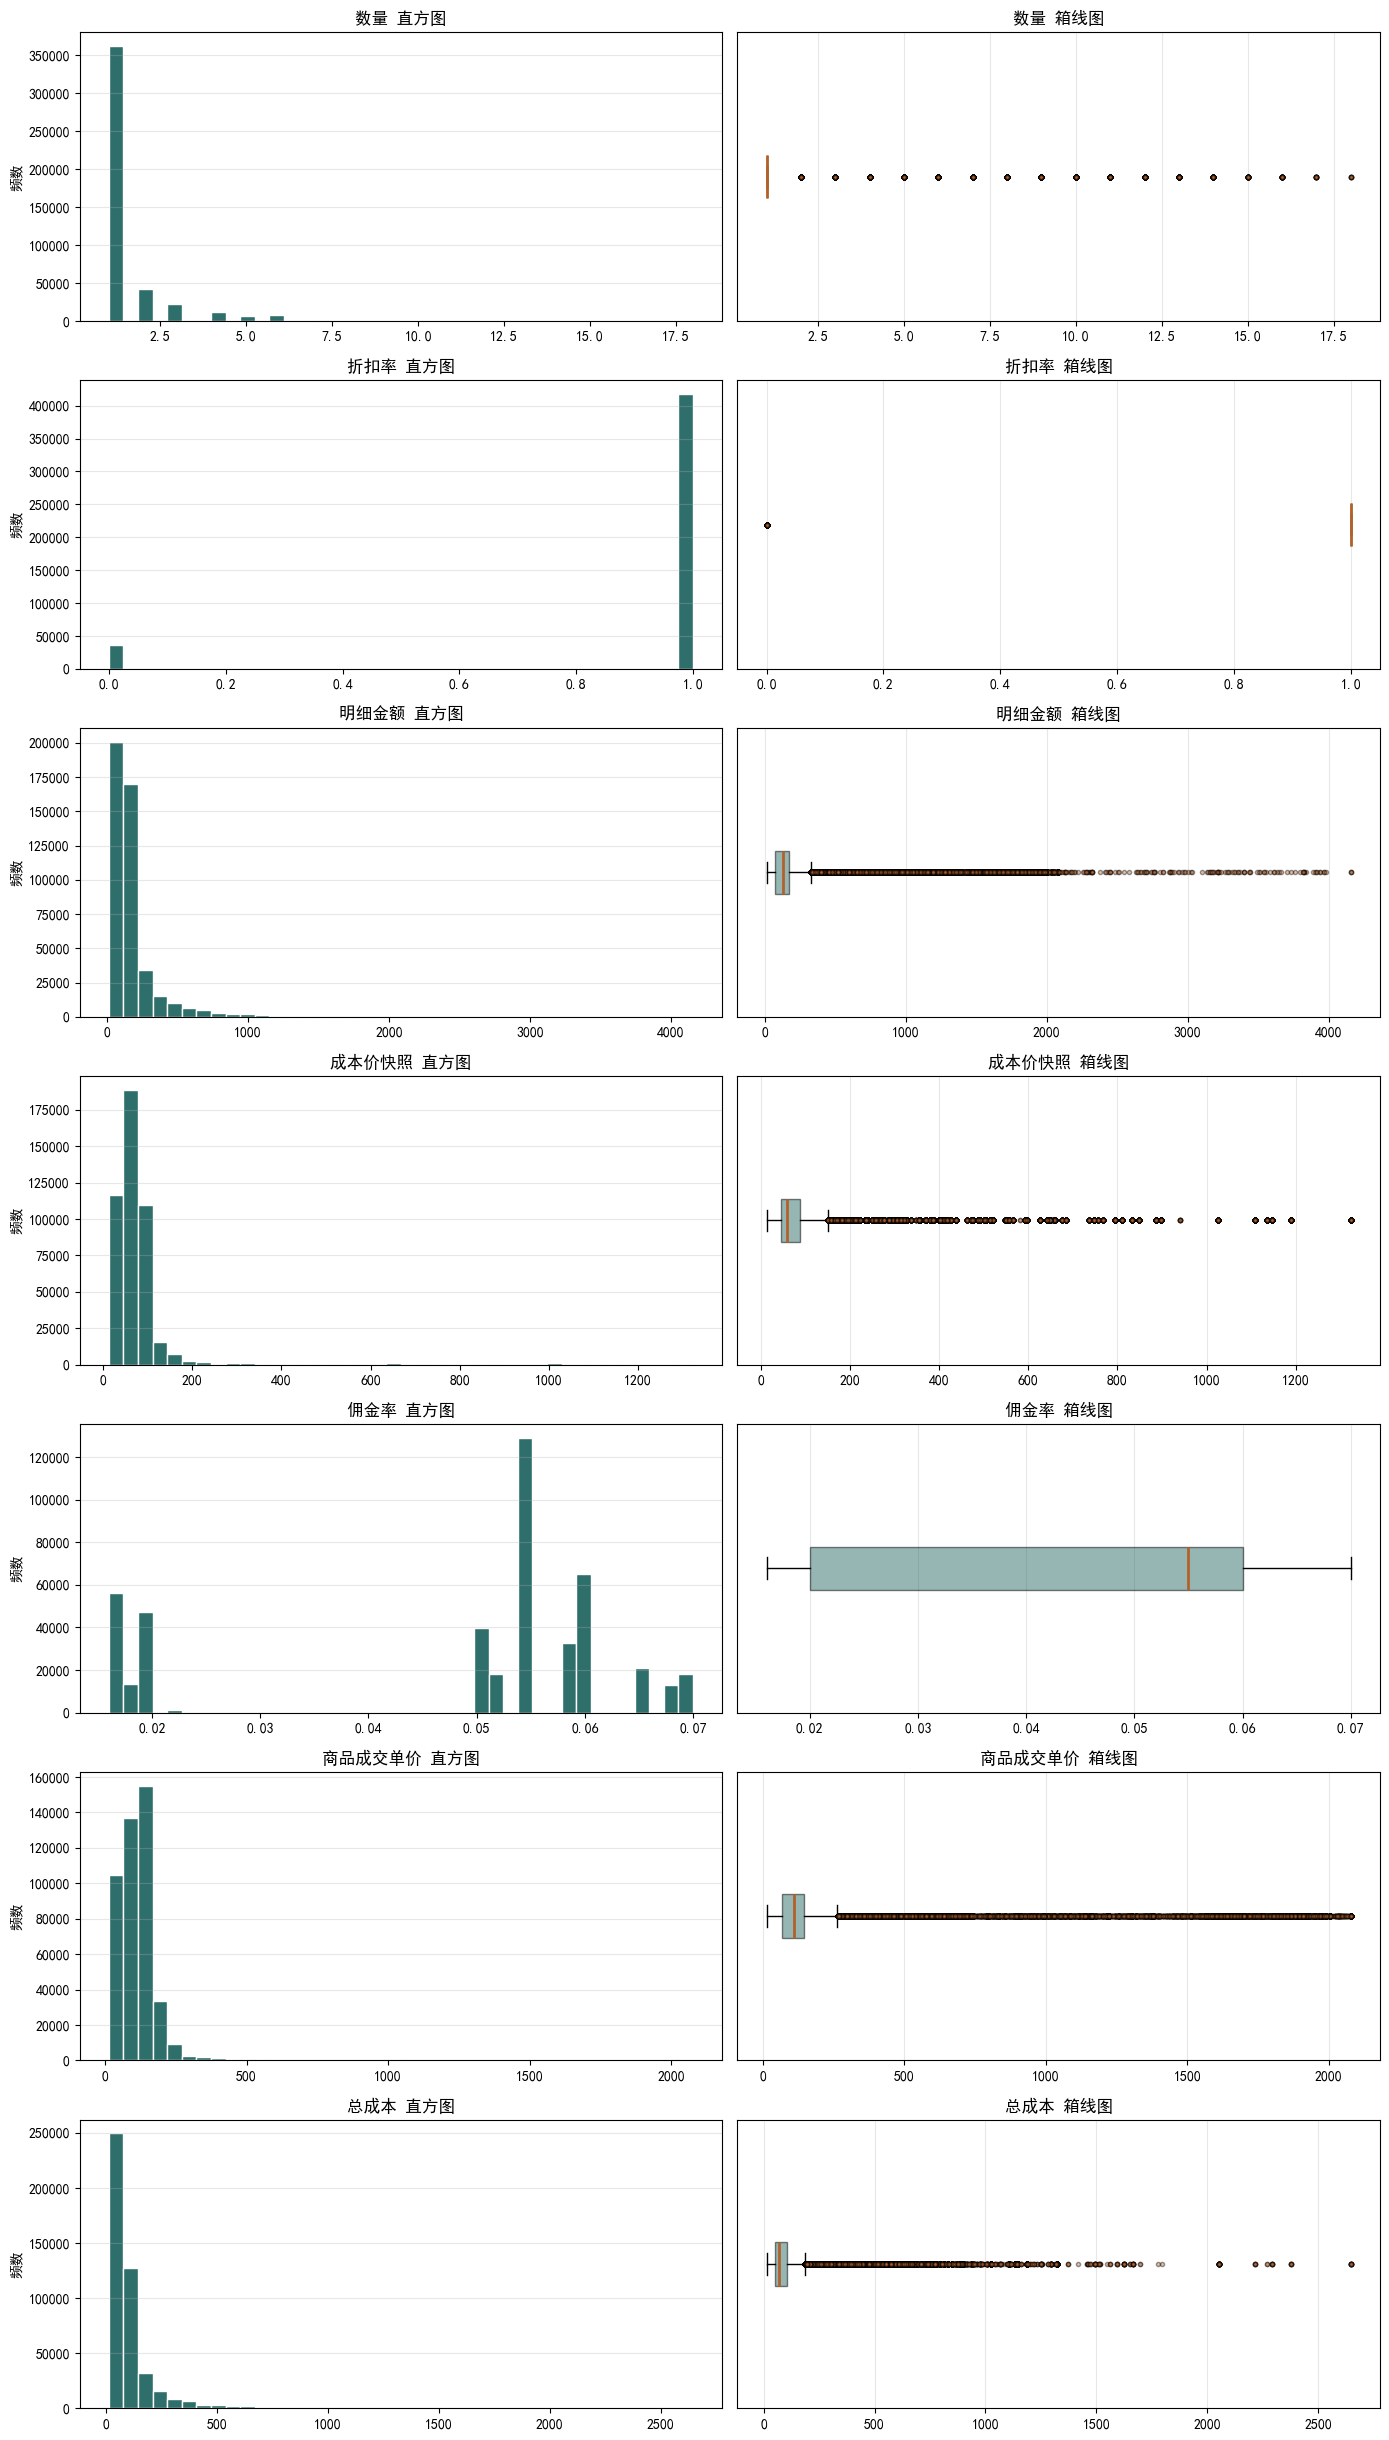

In [8]:
# 设置中文字体
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False
#数据分布
nums = data.select_dtypes(include=[np.number]).columns.tolist()
fig, axes = plt.subplots(len(nums), 2, figsize=(14, 3.5 * len(nums)))
for i, col in enumerate(nums):
    axes[i, 0].hist(data[col].dropna(), bins=40,
                    color="#2f6f6b", edgecolor="white")
    axes[i, 0].set_title(f"{col} 直方图", fontsize=12)
    axes[i, 0].set_ylabel("频数")
    axes[i, 0].grid(axis="y", alpha=0.3)
    bp = axes[i, 1].boxplot(
        data[col].dropna(),
        vert=False,
        patch_artist=True,
        boxprops=dict(facecolor="#2f6f6b", alpha=0.5),
        medianprops=dict(color="#b3612a", linewidth=2),
        flierprops=dict(marker="o", markerfacecolor="#b3612a",
                        markersize=3, alpha=0.4)
    )
    axes[i, 1].set_title(f"{col} 箱线图", fontsize=12)
    axes[i, 1].set_yticks([])
    axes[i, 1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

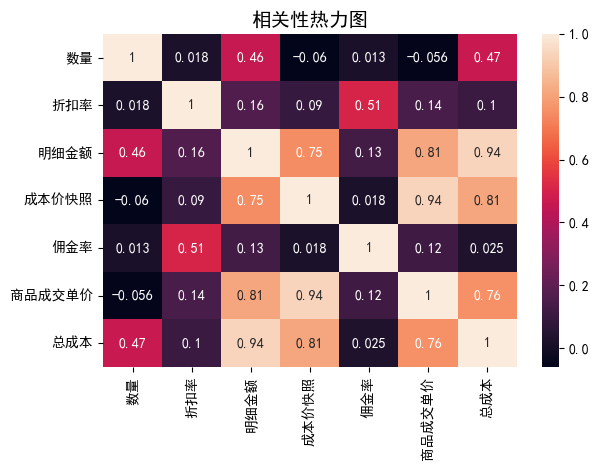

In [9]:
#相关性
corr = data[nums].corr()
sns.heatmap(corr,annot = True)
plt.title("相关性热力图", fontsize=14)
plt.tight_layout()
plt.show()

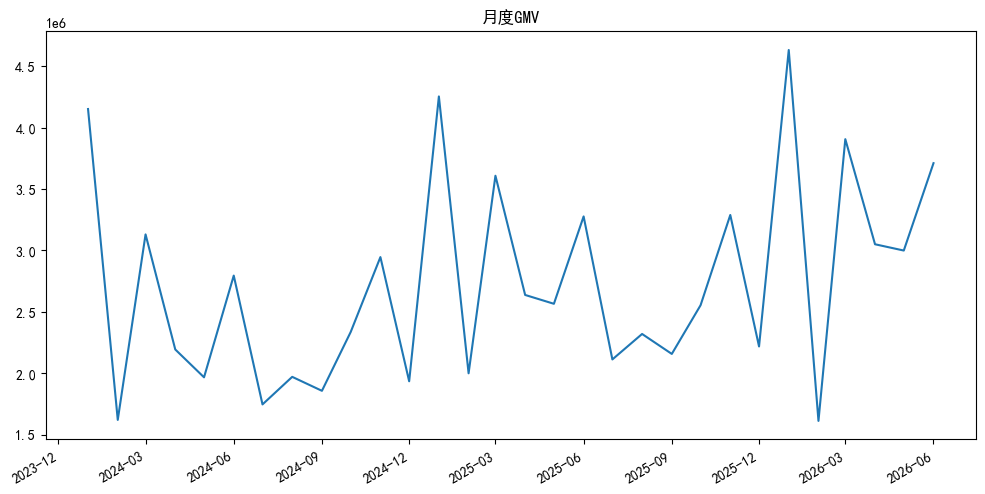

In [10]:
#月度GMV
daily_gmv = data.groupby('日期')['明细金额'].sum()
monthly_gmv = daily_gmv.groupby(daily_gmv.index.to_period('M')).sum()

import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly_gmv.index.to_timestamp(), monthly_gmv.values)
ax.set_title("月度GMV")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()
plt.show()


## S1 新客趋势（背景章节）

**口径**（详见 `doc/指标体系.md`）

- 统计对象：用户，按 `用户id` 去重
- 业务状态：成交 = 订单状态「已完成」；排除 已取消 / 已退款 / 待付款 / 待发货 / 已发货
- 时间边界：自然月；**新客月份 = 用户首次成交所在自然月**
- 新客定义：店铺内首次成交的用户（本数据中一个用户只归属一个店铺，等价于全平台首次成交）
- 单位：新客数（人）、新客 GMV 贡献占比（%）

| 指标 | 口径 | 单位 |
|:--|:--|:--|
| 新客数（月） | 当月首次成交的用户数 | 人 |
| 各渠道新客数（月） | 按**首单**流量渠道拆（九渠道互斥穷尽） | 人 |
| 新客 GMV 贡献占比（月） | 新客当期 GMV ÷ 全平台当期 GMV | % |

**口径备注**：数据起点 2024-01 存在左截断 —— 该月所有成交用户必然全部被判定为新客，故当月新客数与贡献占比（100%）被高估，解读时须剔除该月。


In [11]:
#S1 新客指标：计算已迁到 SQL（sql/20~22），这里只读结果表并做口径对账
#口径见 doc/指标体系.md；重新生成结果表请运行 python py/run_metrics.py
OUT = 'D:/JupyterNoteBook/portfolio/Project2/data/metrics'

def read_metric(name, keys):
    """读一张指标结果表，并把「新客月份」还原成 Period（与迁移前保持一致）。"""
    df = pd.read_csv(f'{OUT}/{name}.csv', encoding='utf-8-sig')
    if '新客月份' in df.columns:
        df['新客月份'] = pd.PeriodIndex(df['新客月份'], freq='M')
    return df.set_index(keys)

s1 = read_metric('s1_新客数_月', ['新客月份'])
s1_new_shop = read_metric('s1_新客数_月_按店铺', ['新客月份', '店铺id'])
s1_new_channel = read_metric('s1_渠道新客数_月', ['新客月份', '流量渠道'])

#口径对账：按渠道 / 按店铺拆分后求和，都应等于全平台新客数
print('校验 各渠道新客数之和 == 全平台 ->',
      bool((s1['新客数'] == s1_new_channel['新客数'].groupby('新客月份').sum()).all()))
print('校验 各店铺新客数之和 == 全平台 ->',
      bool((s1['新客数'] == s1_new_shop['新客数'].groupby('新客月份').sum()).all()))
print(f'月度新客表 {len(s1)} 行，合计新客 {int(s1["新客数"].sum()):,} 人')
print('注1：2024-01 受左截断影响，新客数被高估，解读时须剔除')
print('注2：307 人首单当天有多笔订单，其中 173 人当天渠道不同，图2 的渠道归属对这 173 人不唯一')
print('     （详见 README「已知局限」，该数字由 dq_校验结果 监控）')
s1


校验 各渠道新客数之和 == 全平台 -> True
校验 各店铺新客数之和 == 全平台 -> True
月度新客表 30 行，合计新客 168,360 人
注1：2024-01 受左截断影响，新客数被高估，解读时须剔除
注2：307 人首单当天有多笔订单，其中 173 人当天渠道不同，图2 的渠道归属对这 173 人不唯一
     （详见 README「已知局限」，该数字由 dq_校验结果 监控）


,新客数,新客GMV,全平台GMV,新客人均GMV,新客GMV贡献占比%
新客月份,,,,,
2024-01,13071,3906433,3906433,298.86,100.00
2024-02,3761,1049260,1507289,278.98,69.61
2024-03,7601,2149054,2894760,282.73,74.24
2024-04,4778,1334727,1996921,279.35,66.84
2024-05,4257,1132163,1722745,265.95,65.72
2024-06,8056,1935064,2509573,240.20,77.11
2024-07,4094,1059851,1524704,258.88,69.51
2024-08,4838,1288306,1737070,266.29,74.17
2024-09,4637,1186785,1614017,255.94,73.53


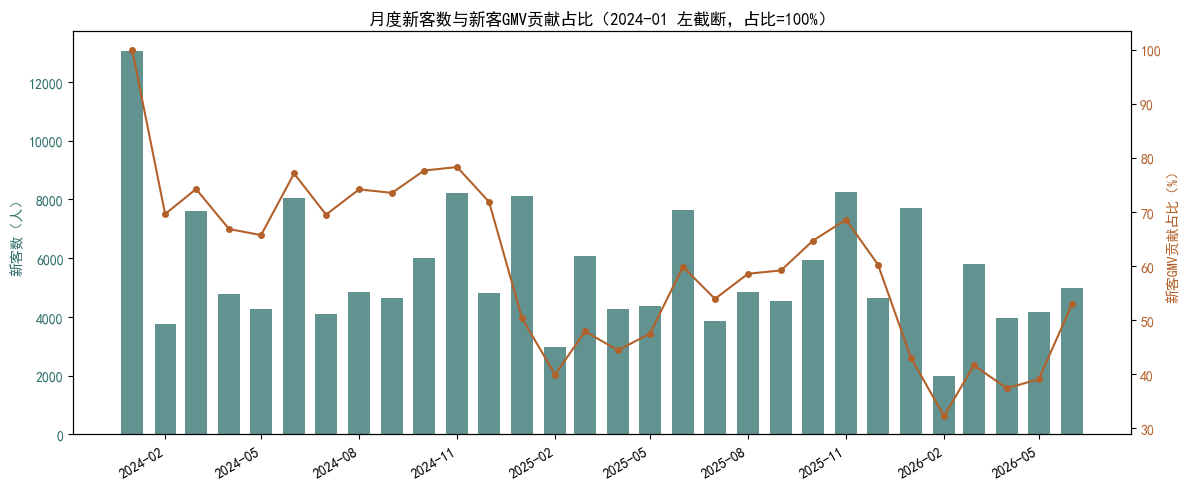

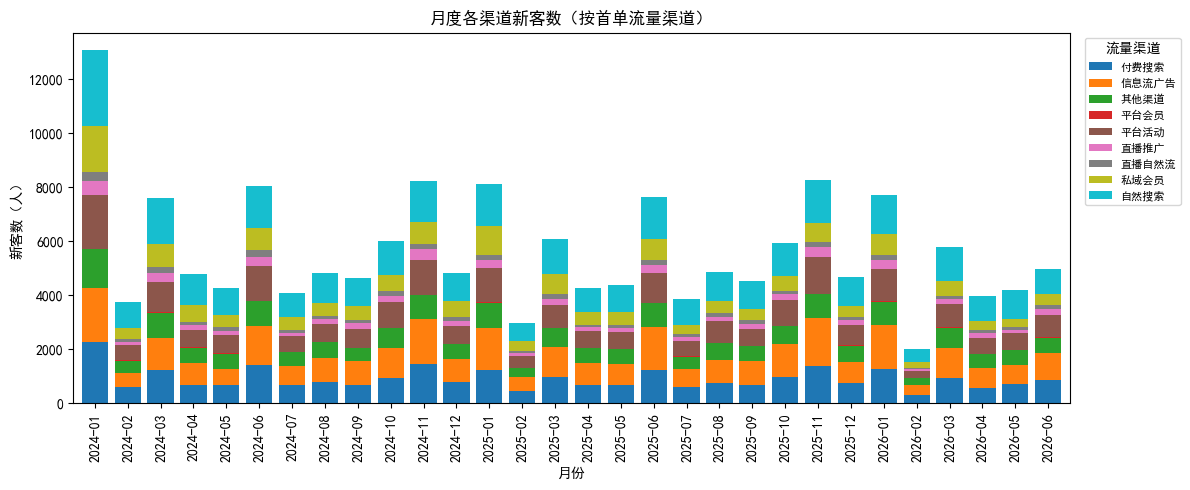

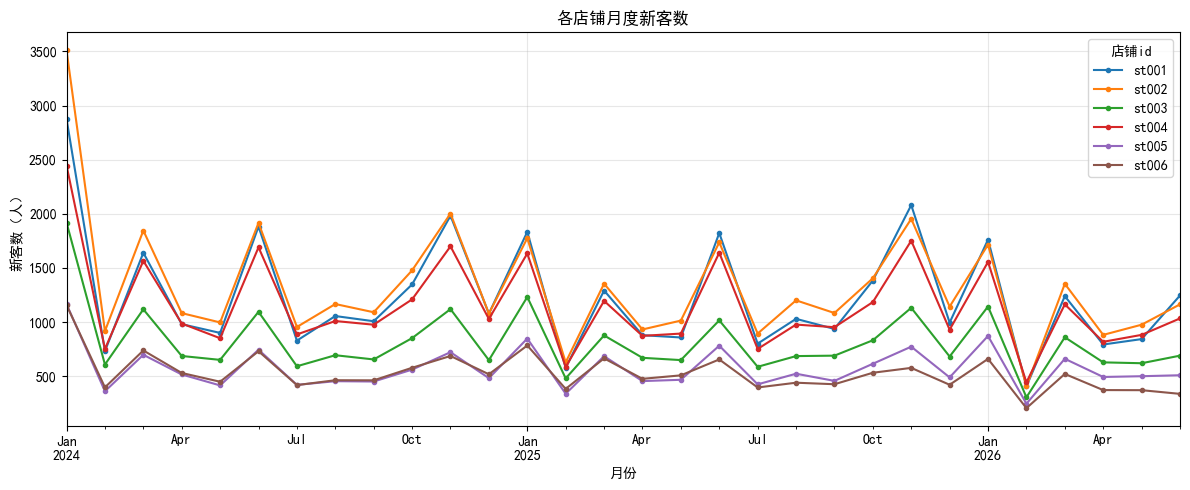

In [12]:
#S1 新客指标可视化
import matplotlib.dates as mdates
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

xm = s1.index.to_timestamp()

#图1 月度新客数与贡献占比
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(xm, s1['新客数'], color='#2f6f6b', alpha=.75, width=20, label='新客数')
ax1.set_ylabel('新客数（人）', color='#2f6f6b')
ax1.tick_params(axis='y', labelcolor='#2f6f6b')
ax2 = ax1.twinx()
ax2.plot(xm, s1['新客GMV贡献占比%'], color='#b3612a', marker='o', ms=4, label='新客GMV贡献占比')
ax2.set_ylabel('新客GMV贡献占比（%）', color='#b3612a')
ax2.tick_params(axis='y', labelcolor='#b3612a')
ax1.set_title('月度新客数与新客GMV贡献占比（2024-01 左截断，占比=100%）')
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

#图2 九渠道新客数结构
pivot_ch = s1_new_channel['新客数'].unstack(fill_value=0)
ax = pivot_ch.plot(kind='bar', stacked=True, figsize=(12, 5), colormap='tab10', width=.8)
ax.set_title('月度各渠道新客数（按首单流量渠道）')
ax.set_xlabel('月份'); ax.set_ylabel('新客数（人）')
ax.legend(title='流量渠道', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

#图3 六店铺月度新客数对比
pivot_shop = s1_new_shop['新客数'].unstack(fill_value=0)
ax = pivot_shop.plot(figsize=(12, 5), marker='o', ms=3)
ax.set_title('各店铺月度新客数')
ax.set_xlabel('月份'); ax.set_ylabel('新客数（人）')
ax.legend(title='店铺id')
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


## RFM 八分层：用户结构与策略方向

**口径**

- 观察点：2026-06-30（数据末日）；窗口：2025-07-01 ~ 2026-06-30（近 12 个月）
- 只统计「已完成」订单；R = 观察点 − 最近一次成交日期（天），F = 窗口内成交订单数，M = 窗口内成交金额
- 活跃用户 = 窗口内有成交；沉睡用户 = 窗口内无成交

**分档阈值**（取窗口中位数，避免全周期稀释近期行为）

| 维度 | 高 / 近 | 低 / 远 |
|:--|:--|:--|
| R | ≤ 160 天 | > 160 天 |
| F | ≥ 2 单（即复购） | = 1 单 |
| M | ≥ 207 元 | < 207 元 |

**八分层与策略**：重要价值 / 一般价值（保持）、重要发展 / 一般发展（发展）、重要保持 / 一般保持 / 重要挽留（挽留）、一般挽留（低成本触达）。对应 OSM：S2 挽留客户 = 重要保持 / 重要挽留，S3 激活沉睡 = 一般发展 / 一般挽留。


In [13]:
#RFM 八分层：计算已迁到 SQL（sql/30~32、40），这里只读结果表并做口径对账
OUT = 'D:/JupyterNoteBook/portfolio/Project2/data/metrics'
reg = pd.read_csv(f'{OUT}/rfm_八分层汇总.csv', encoding='utf-8-sig')
rfm = pd.read_csv(f'{OUT}/rfm_用户明细.csv', encoding='utf-8-sig')
thr = pd.read_csv(f'{OUT}/rfm_阈值.csv', encoding='utf-8-sig').iloc[0]
act = pd.read_csv(f'{OUT}/rfm_活跃沉睡.csv', encoding='utf-8-sig').iloc[0]

n_act = int(act['活跃用户数'])
n_all = int(act['成交用户数'])
n_sleep = int(act['沉睡用户数'])

print(f"窗口 {thr['窗口起']} ~ {thr['窗口止']}（观察点 {thr['观察点']}）")
print(f'成交用户 {n_all:,} 人 -> 活跃 {n_act:,} 人，沉睡 {n_sleep:,} 人')
print(f"分档阈值：R = {thr['R中位']:.1f} 天，F >= {int(thr['F阈值'])} 单，M = {thr['M中位']:.1f} 元")
print('校验 各分层用户数之和 == 活跃用户数 ->', int(reg['用户数'].sum()) == n_act)
print('校验 用户明细行数 == 活跃用户数 ->', len(rfm) == n_act)

reg


窗口 2025-07-01 ~ 2026-06-30（观察点 2026-06-30）
成交用户 168,360 人 -> 活跃 87,547 人，沉睡 80,813 人
分档阈值：R = 160.0 天，F >= 2 单，M = 207.0 元
校验 各分层用户数之和 == 活跃用户数 -> True
校验 用户明细行数 == 活跃用户数 -> True


,分层,人群,用户数,用户占比%,GMV,GMV占比%,人均GMV,平均F,平均R
0,远-低-低,一般挽留客户,23005,26.28,2390107,7.76,104,1.00,253.4
1,近-低-低,一般发展客户,17488,19.98,1852021,6.01,106,1.00,81.7
2,远-低-高,重要挽留客户,15400,17.59,7155864,23.24,465,1.00,252.8
3,近-高-高,重要价值客户,12605,14.40,10603821,34.44,841,2.72,72.6
4,近-低-高,重要发展客户,11993,13.70,5583194,18.13,466,1.00,81.3
5,远-高-高,重要保持客户,3850,4.40,2779637,9.03,722,2.27,222.6
6,近-高-低,一般价值客户,2237,2.56,298353,0.97,133,2.17,77.2
7,远-高-低,一般保持客户,969,1.11,128214,0.42,132,2.07,226.3


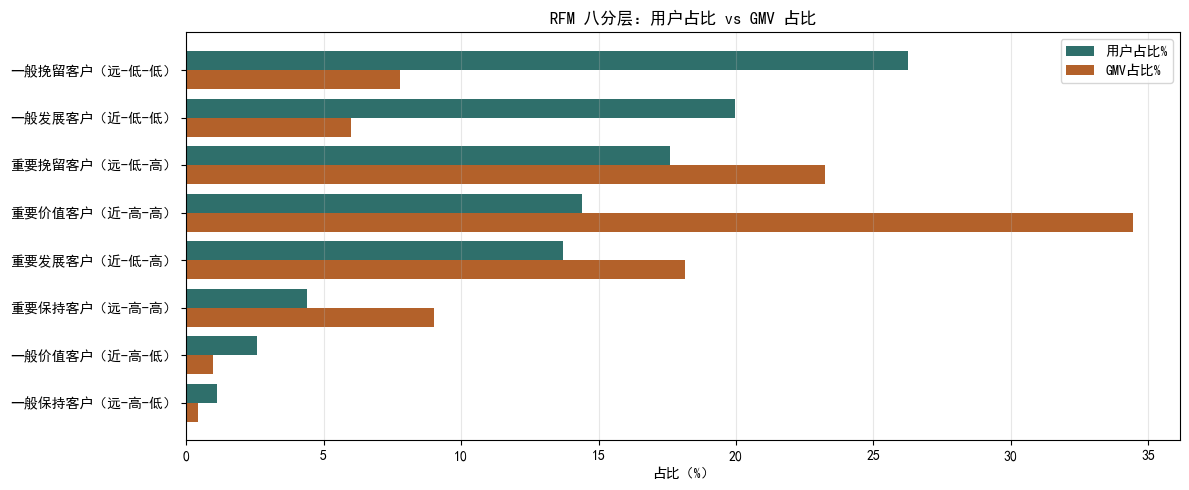

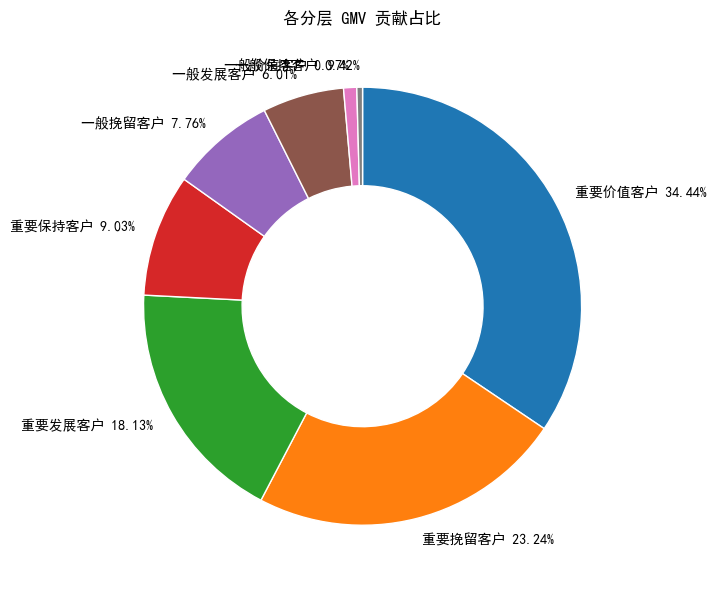

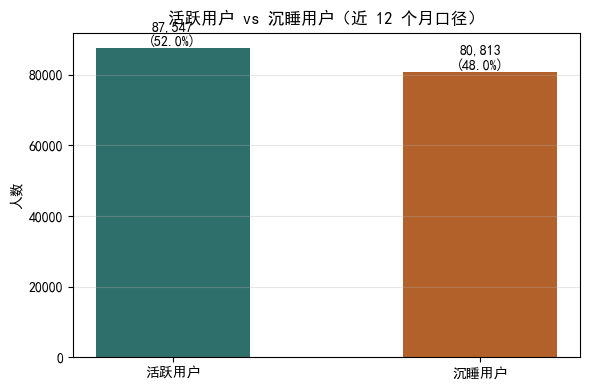

In [14]:
#RFM 分层可视化
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

#图1 用户占比 vs GMV占比
r = reg.sort_values('用户占比%', ascending=False).reset_index(drop=True)
y = np.arange(len(r))
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(y - 0.2, r['用户占比%'], height=.4, color='#2f6f6b', label='用户占比%')
ax.barh(y + 0.2, r['GMV占比%'], height=.4, color='#b3612a', label='GMV占比%')
ax.set_yticks(y)
ax.set_yticklabels([f'{a}（{b}）' for a, b in zip(r['人群'], r['分层'])])
ax.invert_yaxis()
ax.set_xlabel('占比（%）')
ax.set_title('RFM 八分层：用户占比 vs GMV 占比')
ax.legend(); ax.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.show()

#图2 GMV 贡献结构
r2 = reg.sort_values('GMV占比%', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.pie(r2['GMV占比%'], labels=[f'{a} {b}%' for a, b in zip(r2['人群'], r2['GMV占比%'])],
       startangle=90, counterclock=False,
       wedgeprops=dict(width=.45, edgecolor='white'))
ax.set_title('各分层 GMV 贡献占比')
plt.tight_layout(); plt.show()

#图3 活跃 vs 沉睡
n_act2 = n_act  # 活跃/沉睡人数读自 rfm_活跃沉睡.csv（迁移前由 od 反推得到）
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['活跃用户', '沉睡用户'], [n_act2, n_sleep], color=['#2f6f6b', '#b3612a'], width=.5)
for i, v in enumerate([n_act2, n_sleep]):
    ax.text(i, v, f'{v:,}\n({v / (n_act2 + n_sleep) * 100:.1f}%)', ha='center', va='bottom')
ax.set_ylabel('人数'); ax.set_title('活跃用户 vs 沉睡用户（近 12 个月口径）')
ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()
